# Week 6: Solution

1. Check that the vectors of the Fourier basis form an orthonormal basis (number of vectors, scalar products).
This can be done by hand of by code.

Let us do it by hand first. 
Compute the scalar product of any possible par of two Fourier vectors:
$$ \vec{s}^{(k)}\cdot\vec{s}^{(\ell)}
= \frac{2}{N}\sum_{i=0}^{N-1}\sin\left(\frac{2\pi i k}{N}\right)\sin\left(\frac{2\pi i \ell}{N}\right) \\
= \frac{1}{N}'\sum_{i=0}^{N-1}\left[\cos\left(\frac{2\pi i (k-\ell)}{N}\right) - \cos\left(\frac{2\pi i(k+\ell)}{N}\right)\right]
= \left\{\begin{array}{ll} 0 & k\neq\ell \\ 1 & k=\ell\end{array}\right.$$

$$ \vec{c}^{(k)}\cdot\vec{c}^{(\ell)}
= \frac{2}{N}\sum_{i=0}^{N-1}\cos\left(\frac{2\pi i k}{N}\right)\cos\left(\frac{2\pi i \ell}{N}\right) \\
= \frac{1}{N}'\sum_{i=0}^{N-1}\left[\cos\left(\frac{2\pi i (k-\ell)}{N}\right) + \cos\left(\frac{2\pi i(k+\ell)}{N}\right)\right]
= \left\{\begin{array}{ll} 0 & k\neq\ell \\ 1 & k=\ell\end{array}\right.$$

$$ \vec{s}^{(k)}\cdot\vec{c}^{(\ell)}
= \frac{2}{N}\sum_{i=0}^{N-1}\sin\left(\frac{2\pi i k}{N}\right)\cos\left(\frac{2\pi i \ell}{N}\right) \\
= \frac{1}{N}'\sum_{i=0}^{N-1}\left[\sin\left(\frac{2\pi i (k-\ell)}{N}\right) + \sin\left(\frac{2\pi i(k+\ell)}{N}\right)\right] = 0\, .$$

For each row above, the first equality is the definition of the vectors components and of the scalar product.
The second equality uses standard trigonometric properties (see the *Formulaire* from the course *Algèbre Linéaire 1*).

Let us detail the last equalities.
The angles in the sine and the cosine are of the form $\frac{2\pi(k\pm\ell)}{N}i$. 
For fixed values of $k$ and $\ell$, they are the equally spaced along the trigonometric circle. 
In the code below, choose $N$, $k$, and $\ell$ to test it:

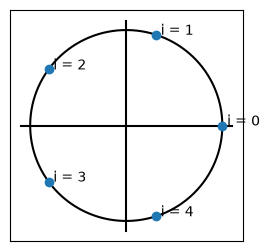

In [5]:
# Choose your parameters
N = 5
k = 2
l = -1 # Adapt the sign to get k+l or k-l

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(3,3))

ax.plot([-1.1,1.1],[0,0],'k',[0,0],[-1.1,1.1],'k')
ax.plot(np.cos(np.linspace(0,2*np.pi,500)),np.sin(np.linspace(0,2*np.pi,500)),'k')

for i in range(N):
    ax.plot(np.cos(2*np.pi*(k+l)*i/N), np.sin(2*np.pi*(k+l)*i/N), 'o', color='C0')
    ax.text(.05 + np.cos(2*np.pi*(k+l)*i/N), np.sin(2*np.pi*(k+l)*i/N), f'i = {i}')
    
ax.set_xticks([])
ax.set_yticks([])

plt.show()

Therefore, their average is precisely at the origin.
In particular, their average horizontal coordinate, i.e., the sum of their cosines, has value zero. 
Same for the vertical coordinate, i.e., the sines.
This explains why the scalar product vanishes when $k\neq\ell$.

There is one exeption. 
When $k=\ell$, the angle $\frac{2\pi(k-\ell)}{N}i=0$ for all $i$. 
Therefore, its cosine has value 1 and its sine has value zero, which explains the distinct cases in the calculations above.

To conclude, we have seen that any two distinct vectors of the basis have scalar prodcut zero, they are then perpendicular and the scalar product of any vector of the basis with it self is one, meaning that it is normalized.
The basis is then orthonormal.

Let us check it now in code. 
Let us build all the vectors in the basis and compute their scalar product. 

The idea will be to build two matrices. 
In the first one $M_1$, we will put all the basis vectors as rows and in the second one $M_2$, we will put all the basis vectors as columns.
We can now check that computing $M_1\cdot M_2$ will compute all possible scalar products simultaneously.
If the basis is orthonormal, the result should be the identity matrix.

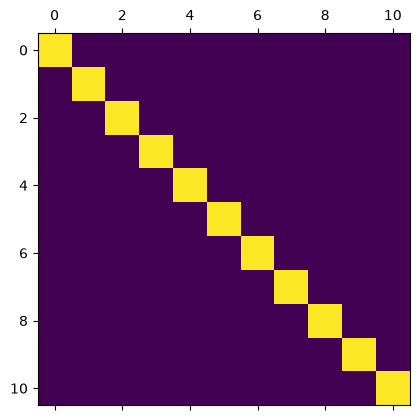

In [19]:
N = 11

M1 = np.zeros((N,N))
M2 = np.zeros((N,N))

c0 = np.ones(N)/np.sqrt(N)

M1[0,:] = c0
M2[:,0] = c0

for k in range(1,int((N+1)/2)):
    ck = np.cos(2*np.pi*np.arange(N)*k/N)*np.sqrt(2/N)
    sk = np.sin(2*np.pi*np.arange(N)*k/N)*np.sqrt(2/N)

    M1[2*k-1,:] = ck
    M1[2*k,:] = sk
    M2[:,2*k-1] = ck
    M2[:,2*k] = sk

I = np.matmul(M1,M2)
plt.matshow(I)

2. Write a script that transforms the output of the FFT algorithm (a list of `a+im*b`) into our list of coefficients `ck` and `sk`.
Embed it in a function `my_DFT` that take a time series as input and returns our DFT as output.

In [19]:
import numpy as np

def my_DFT(X):
    N = len(X)
    if N%2 == 0:
        X = X[:-1]
        N -= 1

    F = np.fft.fft(X)

    myF = np.array([F[0].real/np.sqrt(N),])

    for k in range(1,int((N+1)/2)):
        myF = np.append(myF, F[k].real*np.sqrt(2/N))
        myF = np.append(myF, F[k].imag*np.sqrt(2/N))

    return myF

3. Let $\tilde{X}$ be the DFT of the time series $X$.
   Express the component $X_t$ as a combination of the components of $\tilde{X}$.

**Answer:** By definition, $\tilde{X}$ contains the coefficients of $X$ in the Fourier basis. In our notation, the coefficients (contained in $\tilde{x}$) are 
$$\tilde{X} = (c_0, c_1, s_1, c_2, s_2,...,c_{(N-1)/2}, s_{(N-1)/2})\, ,$$ 
and they are used to represent the time series/vector $X$ in the Fourier basis
$$\mathcal{B} = \left\{\vec{c}^{(0)}, \vec{c}^{(1)}, \vec{s}^{(1)}, \vec{c}^{(2)},...\right\}\, .$$
We can then write $X$ as
$$X = c_0\vec{c}^{(0)} + \sum_{k=1}^{(N-1)/2}c_k\vec{c}^{(k)} + s_k\vec{s}^{(k)}\, .$$
Therefore, focusing on one time step of $X$ can be done by focusing on this same time step in each of the Fourier vectors:
$$X_t = \frac{1}{\sqrt{N}}c_0 + \sqrt{\frac{2}{N}}\sum_{k=1}^{(N-1)/2} c_k\cos\left(\frac{2\pi k t}{N}\right) + s_k\sin\left(\frac{2\pi k t}{N}\right)\, .$$